In [1]:
import pandas as pd
import numpy as np
import json
from config import *
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import mixedlm
import textwrap
from scipy.stats import pearsonr

# EDA Plots

In [9]:
dataset = pd.read_csv("raw_data/All_Dataset.csv")
huesken = dataset[dataset["sources"] == "Huesken"]
huesken.head(3)

,Unnamed: 0,A,B,efficacy,Label,siRNA_seq,mRNA_seq,sources
0,0,A1,BD135193,0.462,0.0,CTAATATGTTAATTGATTTAT,ATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTGAGTTG,Huesken
1,1,A2,BD135193,0.384,0.0,AATATGTTAATTGATTTATAC,AGATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTG...,Huesken
2,2,A3,BD135193,0.514,0.0,GATTTATACAATTCCTTTCAA,CTGCTTATTTTTAGATAAAATTGAAAGGAATTGTATAAATCAATTA...,Huesken


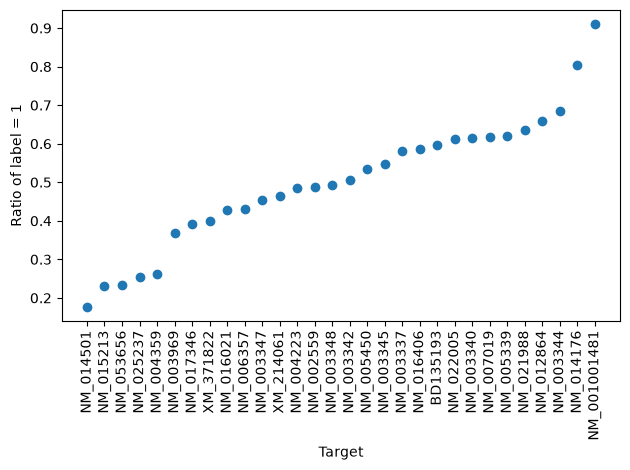

In [10]:
ratio = huesken.groupby("B")["Label"].mean()
ratio = ratio.sort_values()

plt.figure()
plt.scatter(ratio.index, ratio.values)

plt.ylabel("Ratio of label = 1")
plt.xlabel("Target")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

<Axes: xlabel='efficacy', ylabel='Count'>

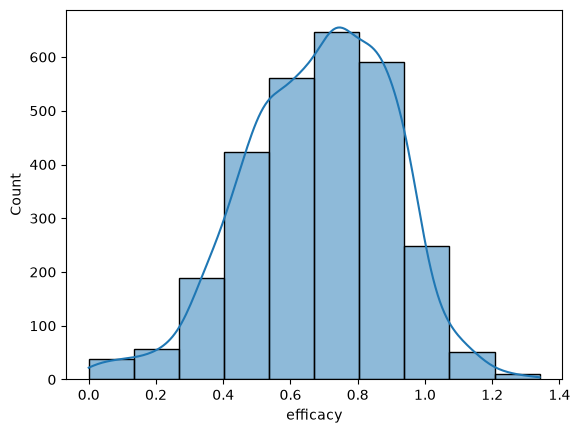

In [11]:
sns.histplot(dataset, x="efficacy", kde=True, bins=10)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


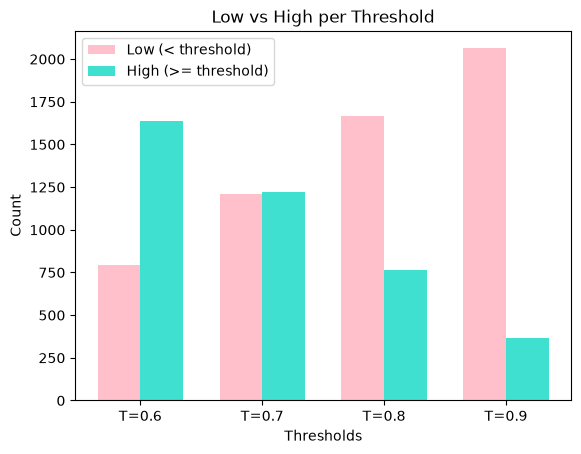

In [12]:
thresholds = [0.6, 0.7, 0.8, 0.9]

low_counts = []
high_counts = []

for t in thresholds:
    low = (huesken["efficacy"] < t).sum()
    high = (huesken["efficacy"] >= t).sum()

    low_counts.append(low)
    high_counts.append(high)


low_color = "pink"
high_color = "turquoise"

# Plot
width = 0.35
x = np.arange(len(thresholds))

plt.figure()
plt.bar(x - width / 2, low_counts, width, label="Low (< threshold)", color=low_color)
plt.bar(
    x + width / 2, high_counts, width, label="High (>= threshold)", color=high_color
)

plt.xticks(x, [f"T={t}" for t in thresholds])
plt.xlabel("Thresholds")
plt.ylabel("Count")
plt.title("Low vs High per Threshold")

plt.legend()
plt.savefig("Thresholds.eps")
plt.show()

# Main Model (Classification)

In [15]:
rows = []
outpath = "LOGO_outfolder/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df.drop(df[df["representation"] == "zcurve_repeat"].index, inplace=True)
df["model"] = df["model"].replace("RF", "Random Forest")
df["model"] = df["model"].replace("LGR", "Logistic Regression")
df["model"] = df["model"].replace("DT", "Decision Tree")
df["model"] = df["model"].replace("SGD", "Stochastic Gradient Descent")
df["model"] = df["model"].replace("KNN", "K-Nearest Neighbour")
df["model"] = df["model"].replace("XGB", "XG Boost")
df["model"] = df["model"].replace("SVC", "Support Vector Classifier")
df

,name,representation,model,metric,value
0,BD135193,GC_count,Support Vector Classifier,roc_auc,0.657407
1,BD135193,GC_count,Support Vector Classifier,pr_auc,0.770932
2,BD135193,GC_count,Support Vector Classifier,precision,0.619048
3,BD135193,GC_count,Support Vector Classifier,recall,0.975000
4,BD135193,GC_count,Support Vector Classifier,fscore,0.757282
...,...,...,...,...,...
12595,XM_371822,atomic_number,Stochastic Gradient Descent,roc_auc,0.496036
12596,XM_371822,atomic_number,Stochastic Gradient Descent,pr_auc,0.377137
12597,XM_371822,atomic_number,Stochastic Gradient Descent,precision,0.303030
12598,XM_371822,atomic_number,Stochastic Gradient Descent,recall,0.172414


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


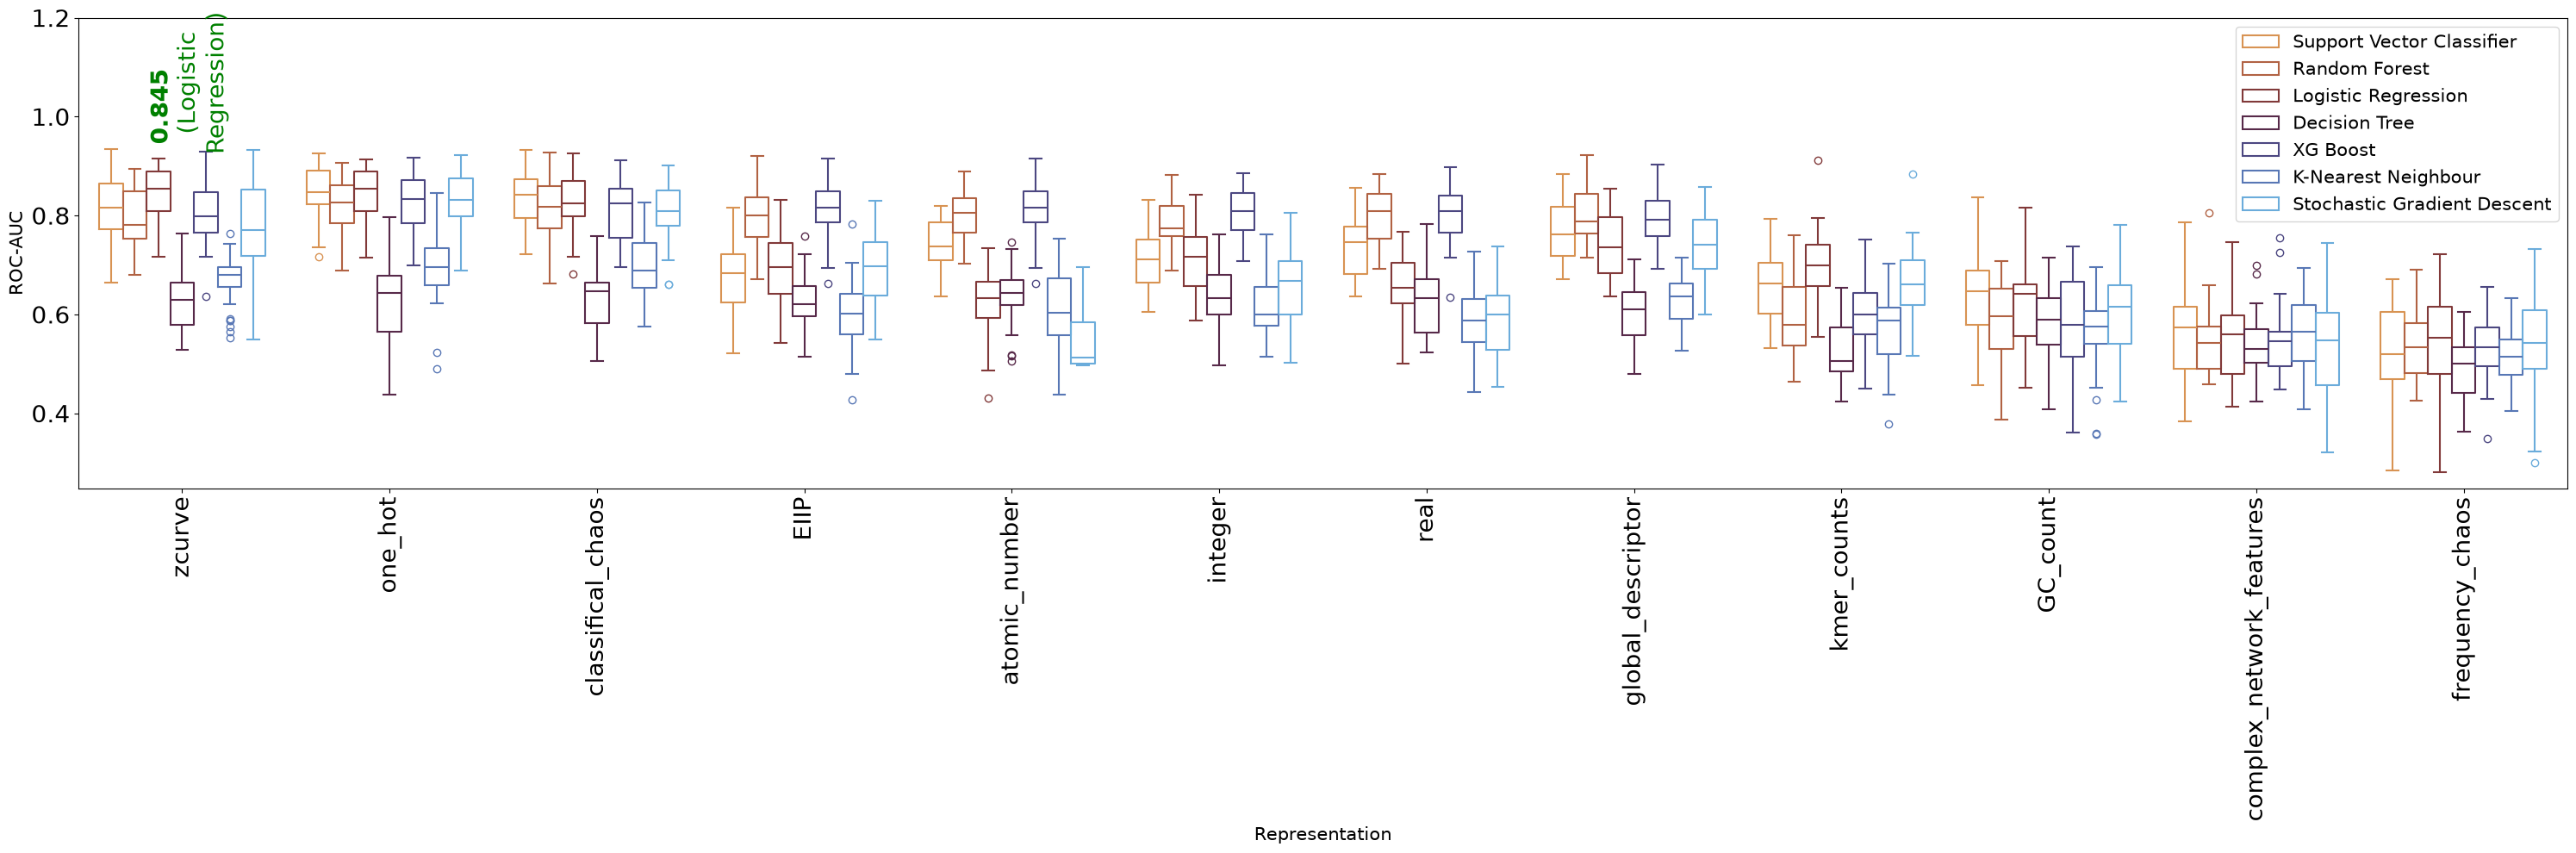

In [16]:
df_auc = df[df["metric"] == "roc_auc"].copy()

# sort representations by their best mean ROC-AUC
rep_order = (
    df_auc.groupby(["representation", "model"])["value"]
    .mean()
    .reset_index()
    .groupby("representation")["value"]
    .max()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(30, 10))
sns.boxplot(
    x="representation",
    y="value",
    data=df_auc,
    hue="model",
    order=rep_order,
    palette="managua",
    fill=False,
)

plt.ylabel("ROC-AUC", size=15)
plt.xlabel("Representation", size=15)
plt.ylim(top=1.2)
plt.xticks(rotation=90, size=20)
plt.yticks(size=20)

# mean values per representation/model
avg_vals = df_auc.groupby(["representation", "model"])["value"].mean().reset_index()

# pick ONLY the single best (first if tie)
best_row = avg_vals.loc[avg_vals["value"].idxmax()]

# box positions
models = list(df_auc["model"].unique())
box_positions = {}
for i, rep in enumerate(rep_order):
    for j, model in enumerate(models):
        box_positions[(rep, model)] = i + (j - (len(models) - 1) / 2) * 0.1

y_max = df_auc["value"].max()

# annotate only the global best
pos = box_positions[(best_row["representation"], best_row["model"])]

plt.text(
    pos,
    y_max + 0.01,
    f"{best_row['value']:.3f}",
    ha="center",
    va="bottom",
    fontsize=20,
    fontweight="bold",
    color="green",
    rotation=90,
)

model_high = "\n".join(textwrap.wrap(best_row["model"], width=10))
plt.text(
    pos + 0.2,
    y_max - 0.01,
    f"({model_high})",
    ha="center",
    va="bottom",
    fontsize=20,
    color="green",
    rotation=90,
)
plt.legend(prop={"size": 15})
plt.tight_layout()
plt.savefig("ROC-AUC_sorted.eps", dpi=300)
plt.show()

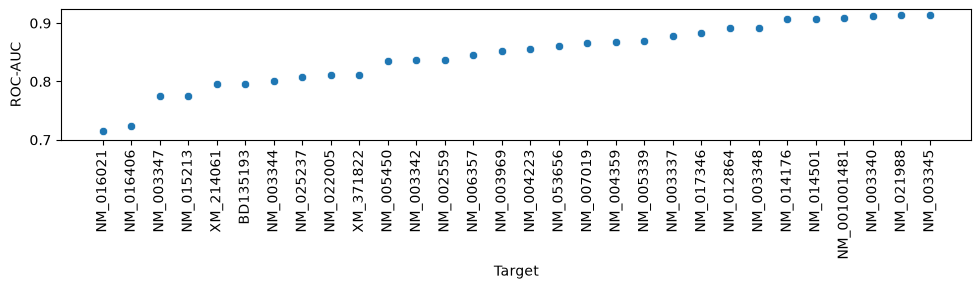

In [17]:
filtered_df = df[
    (df["model"] == "Logistic Regression")
    & (df["representation"] == "zcurve")
    & (df["metric"] == "roc_auc")
]

# Sort by value ascending
filtered_df = filtered_df.sort_values(by="value")
mean_roc = np.round(np.mean(filtered_df["value"]), 3)
# Scatter line plot
plt.figure(figsize=(10, 3))
sns.scatterplot(data=filtered_df, x="name", y="value")
# sns.lineplot(data=filtered_df, x='name', y='value', sort=False)

plt.xticks(rotation=90)
plt.xlabel("Target")
plt.ylabel("ROC-AUC")
plt.ylim(bottom=0.7)
# plt.title(f'ROC-AUC {mean_roc} by Target for Logistic Regression on Z-curves')
plt.tight_layout()
plt.savefig("LGR_ZCURVE_ROC.eps", dpi=300)

# 5' Nucleotide

In [20]:
rows = []
outpath = "single_window_outfolder/"
for filename in ["zcurve_" + str(i) + ".json" for i in range(0, 21)]:
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "window": f"{(b := filename[:-5]).rsplit('_', 1)[0]}_{int(b.rsplit('_', 1)[1]) + 1}",
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,window,model,metric,value
0,BD135193,zcurve_1,RF,roc_auc,0.814815
1,BD135193,zcurve_1,RF,pr_auc,0.842395
2,BD135193,zcurve_1,RF,precision,0.785714
3,BD135193,zcurve_1,RF,recall,0.825000
4,BD135193,zcurve_1,RF,fscore,0.804878
...,...,...,...,...,...
9445,XM_371822,zcurve_21,DT,roc_auc,0.528835
9446,XM_371822,zcurve_21,DT,pr_auc,0.413430
9447,XM_371822,zcurve_21,DT,precision,0.407895
9448,XM_371822,zcurve_21,DT,recall,0.534483


/tmp/ipykernel_1148048/2712806056.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="window", y="value", data=df_auc, palette="managua", fill=False)


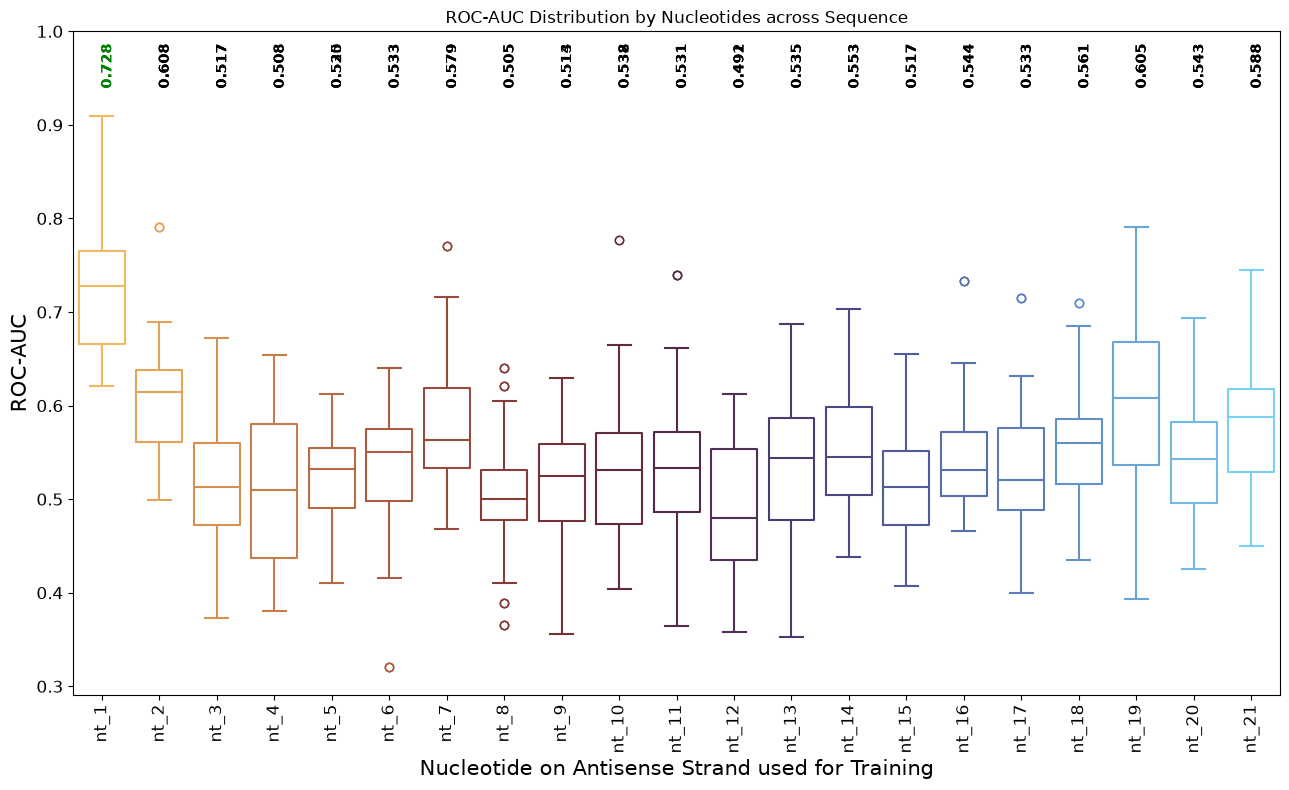

In [21]:
df_auc = df[df["metric"] == "roc_auc"]


plt.figure(figsize=(13, 8))
sns.boxplot(x="window", y="value", data=df_auc, palette="managua", fill=False)
ticks = plt.gca().get_xticks()
labels = [t.get_text() for t in plt.gca().get_xticklabels()]
new_labels = [lbl.replace("zcurve", "nt") for lbl in labels]
plt.ylabel("ROC-AUC", size=15)
plt.xlabel("Nucleotide on Antisense Strand used for Training", size=15)
plt.ylim(top=1)
plt.title("ROC-AUC Distribution by Nucleotides across Sequence")
plt.xticks(ticks, new_labels, size=12, rotation=90)
plt.yticks(size=12)
box_positions = {}
avg_vals = df_auc.groupby(["window", "model"])["value"].mean().reset_index()
y_max = df_auc["value"].max()
# Get positions of the boxes

for i, rep in enumerate(df_auc["window"].unique()):
    box_positions[(rep)] = i + ((1) / 2) * 0.2  # adjust for hue width

max_val = round(avg_vals["value"].max(), 3)
# Annotate means at the top (same height for all)
for _, row in avg_vals.iterrows():
    pos = box_positions[(row["window"])]
    color = "green" if round(row["value"], 3) == max_val else "black"
    plt.text(
        pos,
        y_max + 0.03,
        f"{row['value']:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=color,
        rotation=90,
    )

plt.tight_layout()
plt.savefig("ROC-AUC_Sliding.eps", dpi=300)

# Correlation

In [38]:
data = pd.read_csv(datapath)
huesken_index = data.index[data["sources"] == "Huesken"].tolist()
data = data.loc[huesken_index]
data["shuffled_B"] = np.random.permutation(data["B"])#random shuffles might change values
data.head(5)

,Unnamed: 0,A,B,efficacy,Label,siRNA_seq,mRNA_seq,sources,shuffled_B
0,0,A1,BD135193,0.462,0.0,CTAATATGTTAATTGATTTAT,ATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTGAGTTG,Huesken,NM_012864
1,1,A2,BD135193,0.384,0.0,AATATGTTAATTGATTTATAC,AGATAAAATTGAAAGGAATTGTATAAATCAATTAACATATTAGCTG...,Huesken,NM_017346
2,2,A3,BD135193,0.514,0.0,GATTTATACAATTCCTTTCAA,CTGCTTATTTTTAGATAAAATTGAAAGGAATTGTATAAATCAATTA...,Huesken,NM_001001481
3,3,A4,BD135193,0.364,0.0,CAATTCCTTTCAATTTTATCT,ATTTTGGTCTGCTTATTTTTAGATAAAATTGAAAGGAATTGTATAA...,Huesken,NM_002559
4,4,A5,BD135193,0.522,0.0,CAGACCAAAATTAAATAAGAA,AAATGGAATCTTATGTAACTTTCTTATTTAATTTTGGTCTGCTTAT...,Huesken,NM_003969


### Chi- Square

H0: 2 categorical variables are independent

In [39]:
from scipy.stats import chi2_contingency

tab = pd.crosstab(data["B"], data["Label"])
_, p, _, _ = chi2_contingency(tab)
print("p-value: ", p)

p-value:  5.816607929690996e-42


In [40]:
from scipy.stats import chi2_contingency

tab = pd.crosstab(data["shuffled_B"], data["Label"])
_, p, _, _ = chi2_contingency(tab)
print("p-value: ", p)

p-value:  0.49147126131523255


### ANOVA

H0: All group means equal

In [41]:
groups = [group["efficacy"].values for name, group in data.groupby("B")]
f_stat, p_val = stats.f_oneway(*groups)
print("F-statistic:", f_stat)
print("p-value:", p_val)

F-statistic: 17.109517620484496
p-value: 9.588064056185465e-78


In [42]:
groups = [group["efficacy"].values for name, group in data.groupby("shuffled_B")]
f_stat, p_val = stats.f_oneway(*groups)
print("F-statistic:", f_stat)
print("p-value:", p_val)

F-statistic: 1.0243092732268682
p-value: 0.42967997812618547


### ICC

ICC 0 -> no correlation between observations within group

In [43]:
model = mixedlm("efficacy ~ 1", data, groups=data["B"])
result = model.fit()

print(
    "ICC: " + str(result.cov_re.iloc[0, 0] / (result.cov_re.iloc[0, 0] + result.scale))
)

ICC: 0.16481148262267914


/ceph/users/ahm22224/miniconda3/envs/siRNA_unmod_test2/lib/python3.14/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [44]:
model = mixedlm("efficacy ~ 1", data, groups=data["shuffled_B"])
result = model.fit()

print(
    "ICC: " + str(result.cov_re.iloc[0, 0] / (result.cov_re.iloc[0, 0] + result.scale))
)

ICC: 0.0009488116300712374


/ceph/users/ahm22224/miniconda3/envs/siRNA_unmod_test2/lib/python3.14/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/tmp/ipykernel_1148048/236390277.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="B", y="efficacy", data=data, palette="Set2")


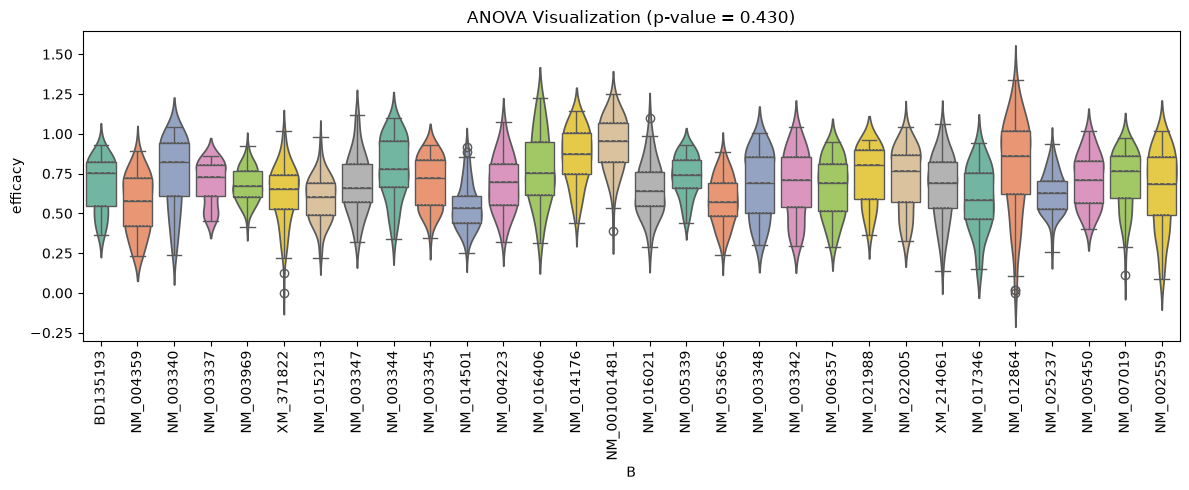

In [45]:
plt.figure(figsize=(12, 5))
sns.boxplot(x="B", y="efficacy", data=data, palette="Set2")
sns.violinplot(
    x="B", y="efficacy", data=data, palette="Set2", inner="quartile", hue="B"
)
plt.title(f"ANOVA Visualization (p-value = {p_val:.3f})")
plt.xlabel("B")
plt.xticks(rotation=90)
plt.ylabel("efficacy")
plt.tight_layout()
plt.savefig("Data Distribution.eps", dpi=300)

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import networkx as nx

np.random.seed(42)

groups = np.unique(data["B"])
tukey = pairwise_tukeyhsd(endog=data["efficacy"], groups=data["B"], alpha=0.05)

similar_pairs = [
    (row[0], row[1]) for row in tukey._results_table.data[1:] if row[-1] == False
]
# Build graph
G = nx.Graph()
G.add_edges_from(similar_pairs)
G.add_nodes_from(groups)

# Find **all maximal cliques** (fully connected groups of any size)
cliques = list(nx.find_cliques(G))
# print("Maximal fully connected clusters:", cliques)

# Plot network
plt.figure(figsize=(10, 7))
pos = nx.shell_layout(G)
colors = plt.cm.tab20(np.linspace(0, 1, len(cliques)))

for i, clique in enumerate(cliques):
    # Draw nodes of the clique
    nx.draw_networkx_nodes(
        G, pos, nodelist=clique, node_color=[colors[i]] * len(clique), node_size=50
    )
    # Draw edges inside the clique
    edges = [
        (clique[m], clique[n])
        for m in range(len(clique))
        for n in range(m + 1, len(clique))
    ]
    nx.draw_networkx_edges(
        G, pos, edgelist=edges, width=1, edge_color=[colors[i]] * len(edges)
    )

# Draw remaining edges not in any clique (if any)
edges_in_cliques = set(
    [
        tuple(sorted(e))
        for clique in cliques
        for e in [
            (clique[m], clique[n])
            for m in range(len(clique))
            for n in range(m + 1, len(clique))
        ]
    ]
)
remaining_edges = [e for e in G.edges if tuple(sorted(e)) not in edges_in_cliques]
nx.draw_networkx_edges(
    G, pos, edgelist=remaining_edges, style="dashed", edge_color="black", width=1
)

nx.draw_networkx_labels(G, pos, font_size=10)
plt.title("Clusters of Fully Similar Groups")
plt.axis("off")
plt.savefig("clusters.eps", dpi=300)

/tmp/ipykernel_1448091/3455095709.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="B", y="efficacy", data=cluster_data, ax=axes[i], palette="Set2")
/tmp/ipykernel_1448091/3455095709.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45)
/tmp/ipykernel_1448091/3455095709.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="B", y="efficacy", data=cluster_data, ax=axes[i], palette="Set2")
/tmp/ipykernel_1448091/3455095709.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using 

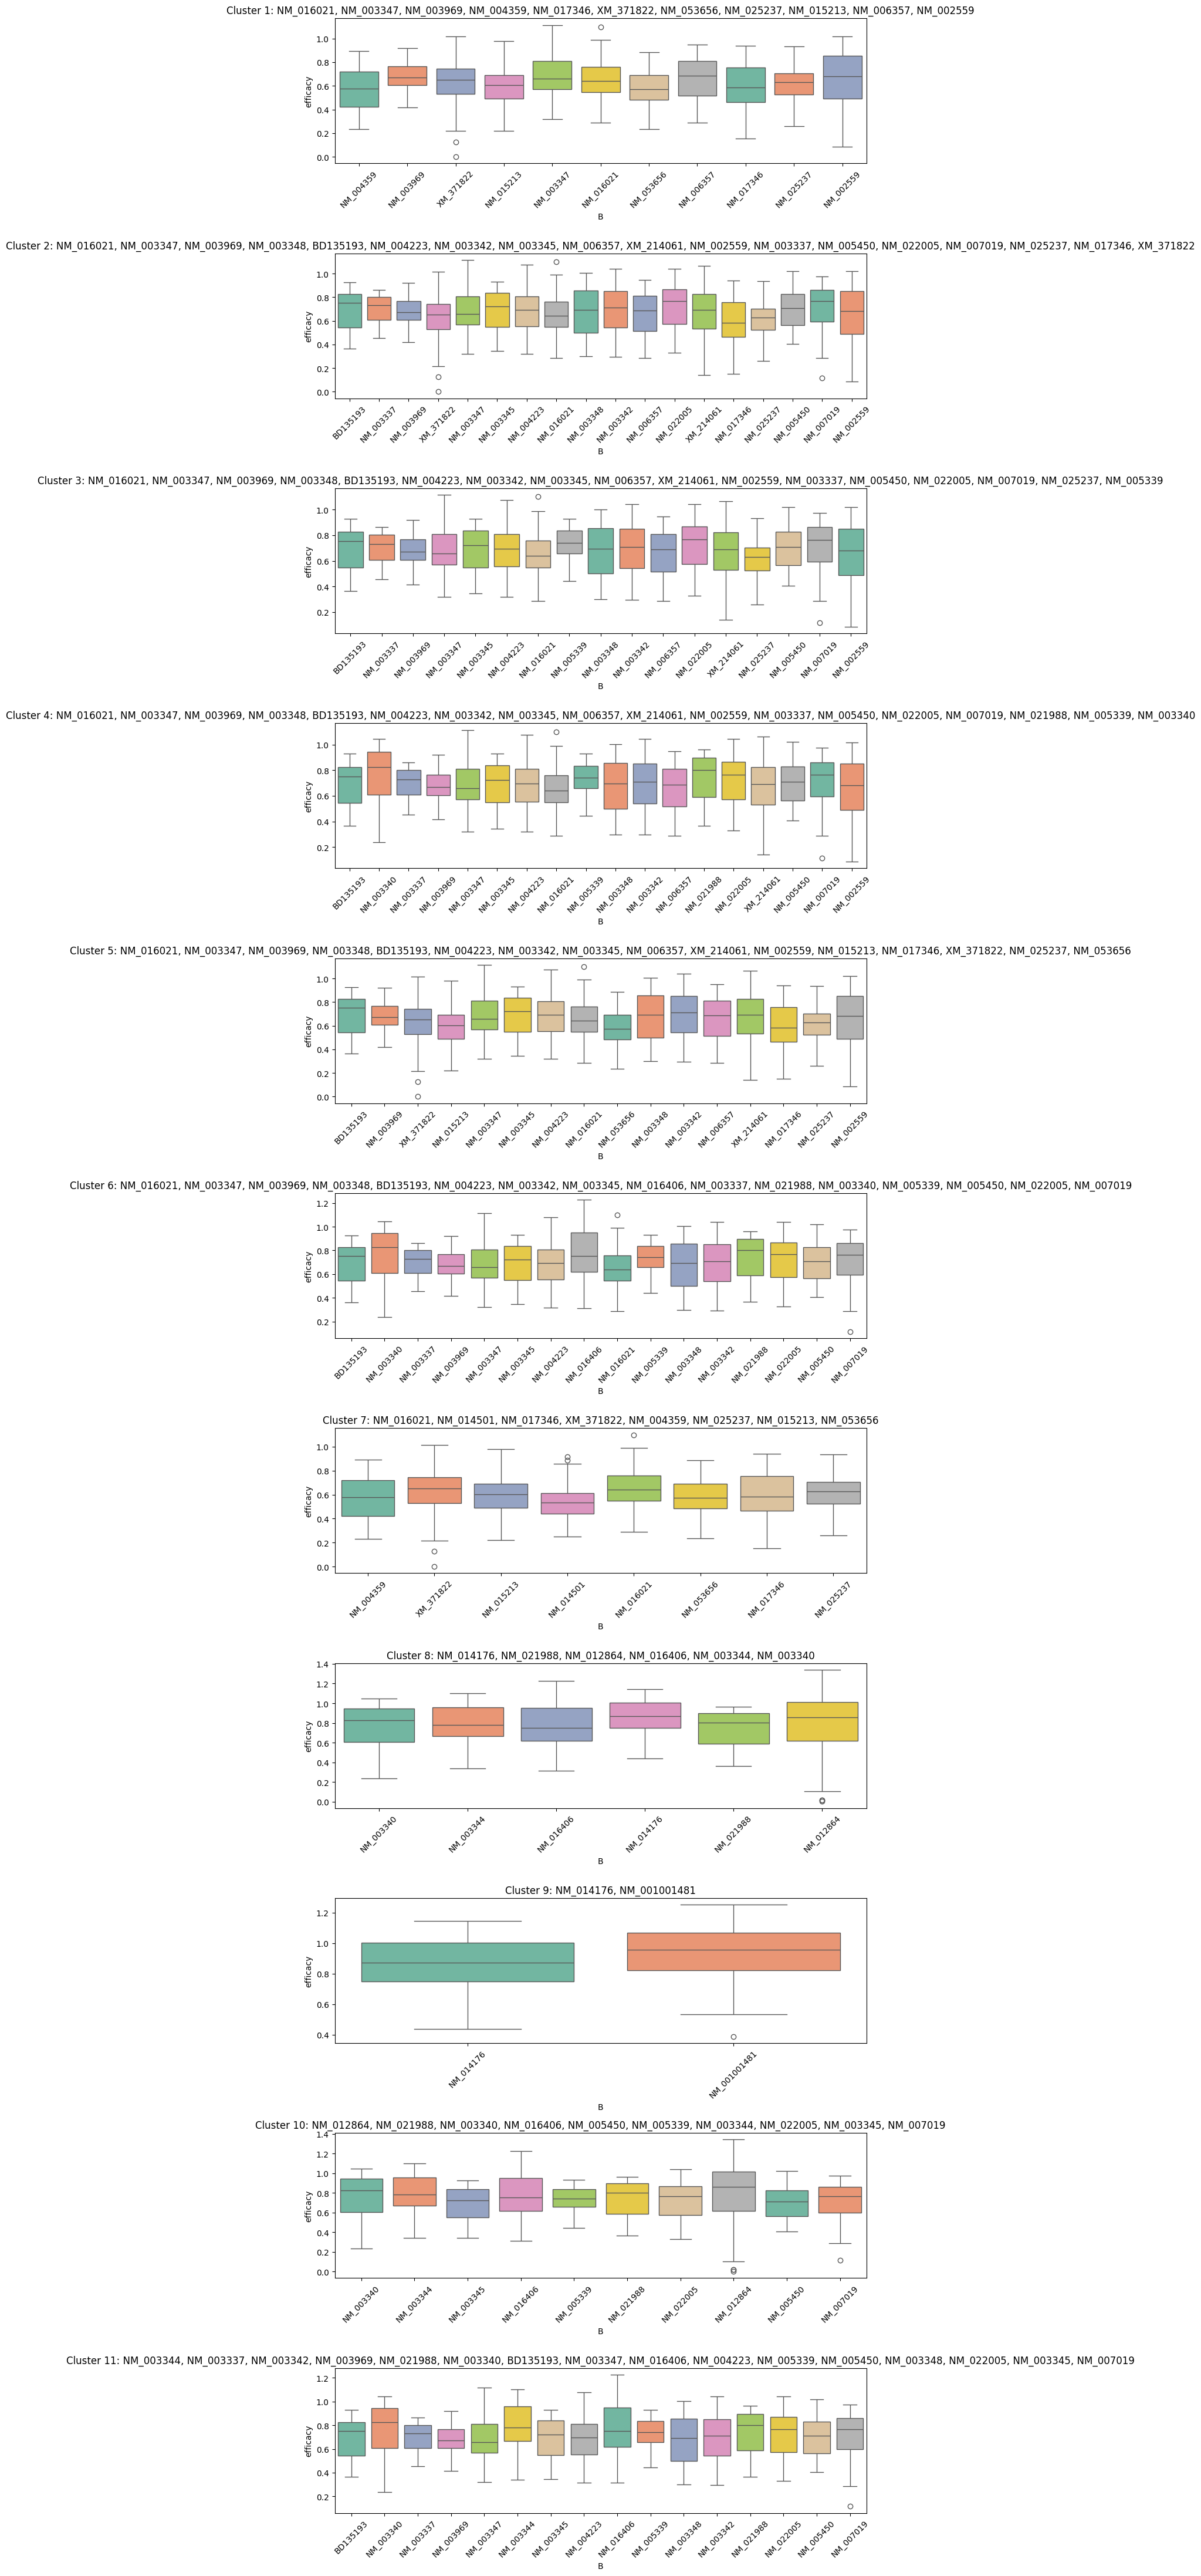

In [20]:
G = nx.Graph()
G.add_edges_from(similar_pairs)
G.add_nodes_from(groups)
cliques = list(nx.find_cliques(G))  # maximal fully connected clusters

# Plot each cluster in a separate subplot
n = len(cliques)
fig, axes = plt.subplots(n, 1, figsize=(10, 4 * n), sharex=False)

if n == 1:
    axes = [axes]  # make iterable if only one cluster

for i, clique in enumerate(cliques):
    cluster_data = data[data["B"].isin(clique)]
    sns.boxplot(x="B", y="efficacy", data=cluster_data, ax=axes[i], palette="Set2")
    # sns.stripplot(x="B", y="efficacy", data=cluster_data, ax=axes[i], color="black", size=5, jitter=True)
    axes[i].set_title(f"Cluster {i + 1}: {', '.join(clique)}")
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.savefig("clusters_Subplot.eps", dpi=300)

# GSS Bias

In [47]:
!pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 104.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn]0m 3/4 [scikit-learn]


/tmp/ipykernel_1148048/663695801.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90, size=10)
/tmp/ipykernel_1148048/663695801.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90, size=10)
/tmp/ipykernel_1148048/663695801.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90, size=10)
/tmp/ipykernel_1148048/663695801.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or us

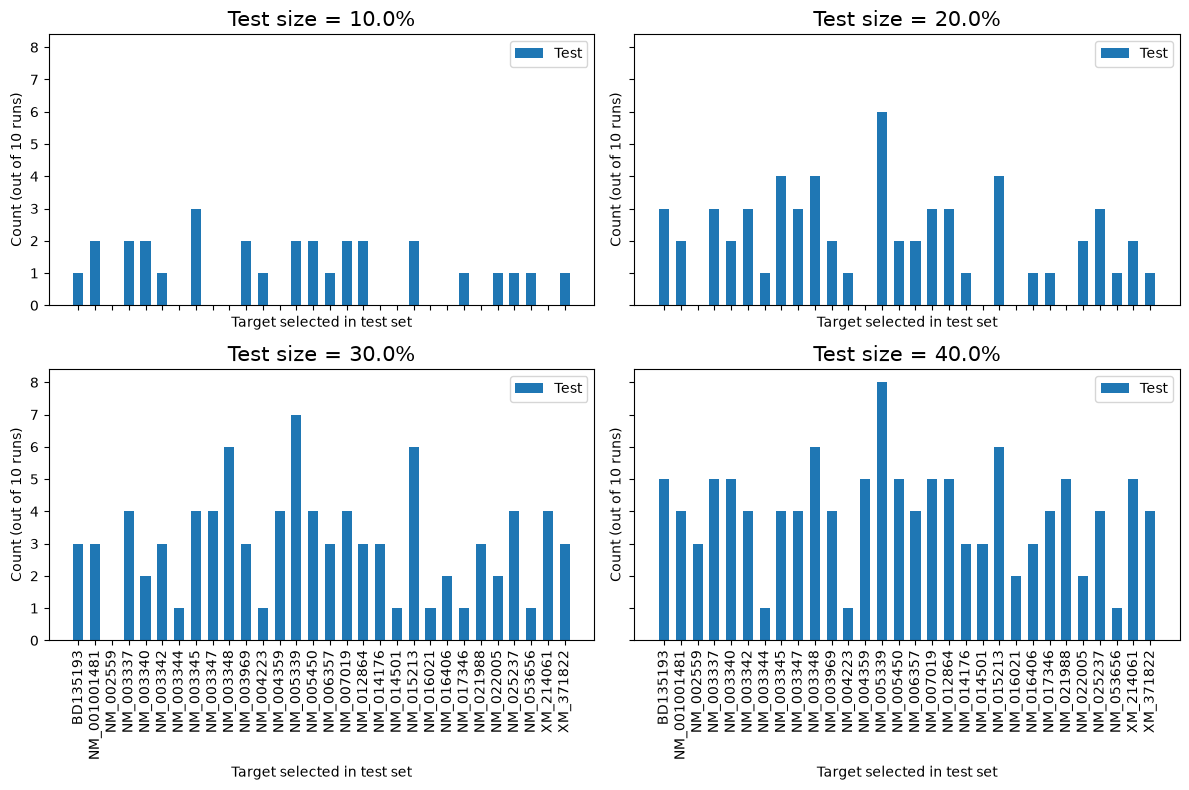

In [48]:
from sklearn.model_selection import GroupShuffleSplit

data = pd.read_csv(datapath)
huesken_index = data.index[data["sources"] == "Huesken"].tolist()
data = data.loc[huesken_index]

X = data["A"]
y = data["Label"]
groups = data["B"]

# Test sizes to explore
test_sizes = [0.1, 0.2, 0.3, 0.4]

# Dictionary of dictionaries to store test counts for each test size
test_results = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True, sharex=True)
axes = axes.flatten()

for i, test_size in enumerate(test_sizes):
    gss = GroupShuffleSplit(n_splits=10, test_size=test_size, random_state=42)

    # Counter for how many times each group is selected into test
    test_counts = {name: 0 for name in np.unique(groups)}

    # Run the splits
    for train_idx, test_idx in gss.split(X, y, groups):
        test_groups = np.unique(groups[test_idx])
        # print(test_groups)
        for g in test_groups:
            test_counts[g] += 1

    test_results[test_size] = test_counts

    axes[i].bar(
        test_results[test_size].keys(),
        test_results[test_size].values(),
        width=0.6,
        label="Test",
    )

    axes[i].set_xlabel("Target selected in test set")
    axes[i].set_ylabel("Count (out of 10 runs)")
    axes[i].set_title(f"Test size = {test_size * 100}%", size=15)
    axes[i].set_xticklabels(test_results[test_size].keys(), rotation=90, size=10)
    # axes[i].set_yticklabels([0,2,4,6,8,10],size=12)
    # axes[i].set_xticklabels([f"g{l}" for l in labels])
    axes[i].legend()

plt.tight_layout()
plt.savefig("GSS_bias.eps")
plt.show()

# Fixed Size test

In [49]:
data = pd.read_csv(datapath)
huesken_index = data.index[data["sources"] == "Huesken"].tolist()
data = data.loc[huesken_index]
ratio = data.groupby("B")["Label"].mean()
freq_df = data["B"].value_counts().reset_index()
freq_df.columns = ["Target", "Frequency"]
freq_df["Ratio"] = ratio.values
freq_df

,Target,Frequency,Ratio
0,NM_012864,150,0.597015
1,XM_371822,145,0.910256
2,XM_214061,144,0.488889
3,NM_015213,126,0.582278
4,NM_002559,90,0.615385
5,NM_003337,79,0.506329
6,NM_014501,79,0.685714
7,NM_005339,79,0.546875
8,NM_003348,79,0.452830
9,NM_003342,79,0.493671


In [50]:
rows = []
outpath = "other_CV_tests/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,representation,model,metric,value
0,50_1,zcurve_databound,SVC,roc_auc,0.614901
1,50_1,zcurve_databound,SVC,pr_auc,0.618184
2,50_1,zcurve_databound,SVC,precision,0.595041
3,50_1,zcurve_databound,SVC,recall,0.716418
4,50_1,zcurve_databound,SVC,fscore,0.650113
...,...,...,...,...,...
16550,XM_371822,zcurve_fixed,SGD,roc_auc,0.580757
16551,XM_371822,zcurve_fixed,SGD,pr_auc,0.445940
16552,XM_371822,zcurve_fixed,SGD,precision,0.450000
16553,XM_371822,zcurve_fixed,SGD,recall,0.620690


0.844


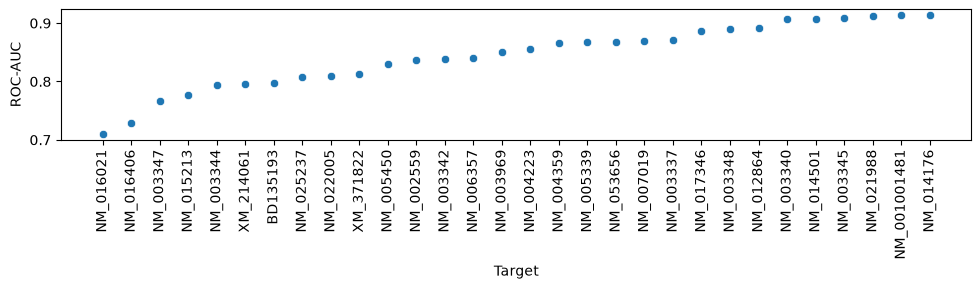

In [51]:
filtered_df = df[
    (df["model"] == "LGR")
    & (df["representation"] == "zcurve_fixed")
    & (df["metric"] == "roc_auc")
]

# Sort by value ascending
filtered_df = filtered_df.sort_values(by="value")
mean_roc = np.round(np.mean(filtered_df["value"]), 3)
print(mean_roc)
# Scatter line plot
plt.figure(figsize=(10, 3))
sns.scatterplot(data=filtered_df, x="name", y="value")
# sns.lineplot(data=filtered_df, x='name', y='value', sort=False)
plt.ylim(bottom=0.7)
plt.xticks(rotation=90)
plt.xlabel("Target")
plt.ylabel("ROC-AUC")
# plt.title(f'ROC-AUC {mean_roc} by Target for Logistic Regression on Z-curves (Fixed Size Training Data)')
plt.tight_layout()
plt.savefig("LGR_ZCURVE_ROC_FIXEDSIZE.eps", dpi=300)

In [52]:
df_merged = freq_df.merge(filtered_df, left_on="Target", right_on="name", how="left")

df_merged = df_merged.rename(columns={"value": "roc-auc"})
df_merged

,Target,Frequency,Ratio,name,representation,model,metric,roc-auc
0,NM_012864,150,0.597015,NM_012864,zcurve_fixed,LGR,roc_auc,0.890869
1,XM_371822,145,0.910256,XM_371822,zcurve_fixed,LGR,roc_auc,0.812128
2,XM_214061,144,0.488889,XM_214061,zcurve_fixed,LGR,roc_auc,0.795891
3,NM_015213,126,0.582278,NM_015213,zcurve_fixed,LGR,roc_auc,0.776040
4,NM_002559,90,0.615385,NM_002559,zcurve_fixed,LGR,roc_auc,0.837451
5,NM_003337,79,0.506329,NM_003337,zcurve_fixed,LGR,roc_auc,0.871542
6,NM_014501,79,0.685714,NM_014501,zcurve_fixed,LGR,roc_auc,0.907692
7,NM_005339,79,0.546875,NM_005339,zcurve_fixed,LGR,roc_auc,0.868027
8,NM_003348,79,0.452830,NM_003348,zcurve_fixed,LGR,roc_auc,0.889744
9,NM_003342,79,0.493671,NM_003342,zcurve_fixed,LGR,roc_auc,0.837821


In [53]:
corr, pval = pearsonr(df_merged["Frequency"], df_merged["roc-auc"])
print("correlation:", corr)
print("p-value:", pval)

correlation: -0.007439941689431753
p-value: 0.9688751232554246


In [54]:
corr, pval = pearsonr(df_merged["Ratio"], df_merged["roc-auc"])
print("correlation:", corr)
print("p-value:", pval)

correlation: 0.13939538982973232
p-value: 0.46254899690851536


# Test on Rest

In [55]:
full_data = pd.read_csv(datapath)
freq_df = full_data["sources"].value_counts().reset_index()
freq_df.columns = ["Source", "Frequency"]
freq_df

,Source,Frequency
0,Huesken,2431
1,Other,385


In [56]:
rows = []
outpath = "other_CV_tests/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,representation,model,metric,value
0,50_1,zcurve_databound,SVC,roc_auc,0.614901
1,50_1,zcurve_databound,SVC,pr_auc,0.618184
2,50_1,zcurve_databound,SVC,precision,0.595041
3,50_1,zcurve_databound,SVC,recall,0.716418
4,50_1,zcurve_databound,SVC,fscore,0.650113
...,...,...,...,...,...
16550,XM_371822,zcurve_fixed,SGD,roc_auc,0.580757
16551,XM_371822,zcurve_fixed,SGD,pr_auc,0.445940
16552,XM_371822,zcurve_fixed,SGD,precision,0.450000
16553,XM_371822,zcurve_fixed,SGD,recall,0.620690


In [57]:
filtered_df = df[
    (df["model"] == "LGR")
    & (df["representation"] == "zcurve_holdout")
    & (df["metric"] == "roc_auc")
]

print(filtered_df)

        name  representation model   metric     value
15130  Other  zcurve_holdout   LGR  roc_auc  0.752785


# Data Bound Test

In [3]:
rows = []
outpath = "other_CV_tests/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,representation,model,metric,value
0,50_1,zcurve_databound,SVC,roc_auc,0.614901
1,50_1,zcurve_databound,SVC,pr_auc,0.618184
2,50_1,zcurve_databound,SVC,precision,0.595041
3,50_1,zcurve_databound,SVC,recall,0.716418
4,50_1,zcurve_databound,SVC,fscore,0.650113
...,...,...,...,...,...
16550,XM_371822,zcurve_fixed,SGD,roc_auc,0.580757
16551,XM_371822,zcurve_fixed,SGD,pr_auc,0.445940
16552,XM_371822,zcurve_fixed,SGD,precision,0.450000
16553,XM_371822,zcurve_fixed,SGD,recall,0.620690


In [4]:
filtered_df = df[(df["model"] == "LGR") & (df["representation"] == "zcurve_databound")]

filtered_df["name"] = filtered_df["name"].str.extract(r"^([^_]+)").astype(int)

filtered_df

,name,representation,model,metric,value
10,50,zcurve_databound,LGR,roc_auc,0.640358
11,50,zcurve_databound,LGR,pr_auc,0.646982
12,50,zcurve_databound,LGR,precision,0.609302
13,50,zcurve_databound,LGR,recall,0.651741
14,50,zcurve_databound,LGR,fscore,0.629808
...,...,...,...,...,...
15095,2400,zcurve_databound,LGR,roc_auc,0.752028
15096,2400,zcurve_databound,LGR,pr_auc,0.760845
15097,2400,zcurve_databound,LGR,precision,0.675556
15098,2400,zcurve_databound,LGR,recall,0.756219


In [8]:
import matplotlib.colors as mcolors
import numpy as np
def blend_light(color, alpha=0.2, bg_color='white'):
    fg = np.array(mcolors.to_rgb(color))
    bg = np.array(mcolors.to_rgb(bg_color))
    return tuple(alpha * fg + (1 - alpha) * bg)



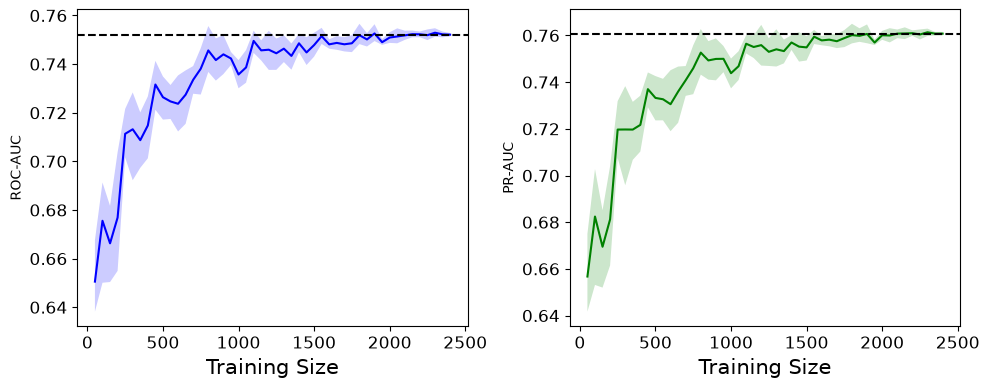

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False, sharex=True)
roc_df = filtered_df[filtered_df["metric"] == "roc_auc"]
main_color = "blue" 
ci_color = blend_light(main_color, alpha=0.2)
sns.lineplot(
    data=roc_df, x="name", y="value", ax=axes[0],
    color="blue", errorbar="ci",
    err_kws={"facecolor": ci_color, "edgecolor": "none", "alpha": 1.0}
)
axes[0].axhline(roc_df.loc[roc_df["name"] == 2400, "value"].mean(), ls="--", c="Black")
axes[0].set_xlabel("Training Size", size=15)
axes[0].tick_params(axis="y", labelsize=12)
axes[0].set_ylabel("ROC-AUC")
axes[0].tick_params(axis="x", labelsize=12)
pr_df = filtered_df[filtered_df["metric"] == "pr_auc"]
main_color = "green" 
ci_color = blend_light(main_color, alpha=0.2)
sns.lineplot(
    data=pr_df, x="name", y="value", ax=axes[1],
    color="green", errorbar="ci",
   err_kws={"facecolor": ci_color, "edgecolor": "none", "alpha": 1.0}
)
axes[1].axhline(pr_df.loc[pr_df["name"] == 2400, "value"].mean(), ls="--", c="Black")
axes[1].set_xlabel("Training Size", size=15)
axes[1].tick_params(axis="x", labelsize=12)
axes[1].tick_params(axis="y", labelsize=12)
axes[1].set_ylabel("PR-AUC")
plt.tight_layout()
plt.savefig("images/data bound.eps")
plt.show()

# LOGO vs K-Fold

In [61]:
rows = []
outpath = "other_CV_tests/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,representation,model,metric,value
0,50_1,zcurve_databound,SVC,roc_auc,0.614901
1,50_1,zcurve_databound,SVC,pr_auc,0.618184
2,50_1,zcurve_databound,SVC,precision,0.595041
3,50_1,zcurve_databound,SVC,recall,0.716418
4,50_1,zcurve_databound,SVC,fscore,0.650113
...,...,...,...,...,...
16550,XM_371822,zcurve_fixed,SGD,roc_auc,0.580757
16551,XM_371822,zcurve_fixed,SGD,pr_auc,0.445940
16552,XM_371822,zcurve_fixed,SGD,precision,0.450000
16553,XM_371822,zcurve_fixed,SGD,recall,0.620690


In [62]:
filtered_df = df[
    (df["model"] == "LGR")
    & (
        (df["representation"] == "zcurve_kfold")
        | (df["representation"] == "zcurve_fixed")
    )
    & (df["metric"] == "roc_auc")
]


filtered_df

,name,representation,model,metric,value
15165,Fold_0,zcurve_kfold,LGR,roc_auc,0.811943
15200,Fold_1,zcurve_kfold,LGR,roc_auc,0.821581
15235,Fold_2,zcurve_kfold,LGR,roc_auc,0.802938
15270,Fold_3,zcurve_kfold,LGR,roc_auc,0.799756
15305,Fold_4,zcurve_kfold,LGR,roc_auc,0.849546
15340,Fold_5,zcurve_kfold,LGR,roc_auc,0.814592
15375,Fold_6,zcurve_kfold,LGR,roc_auc,0.845405
15410,Fold_7,zcurve_kfold,LGR,roc_auc,0.892247
15445,Fold_8,zcurve_kfold,LGR,roc_auc,0.823804
15480,Fold_9,zcurve_kfold,LGR,roc_auc,0.835593


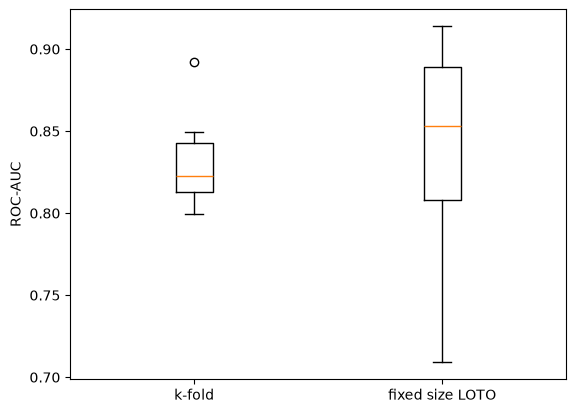

In [63]:
rep_map = {"zcurve_kfold": "k-fold", "zcurve_fixed": "fixed size LOTO"}

filtered_df["rep_label"] = filtered_df["representation"].map(rep_map)
order = ["k-fold", "fixed size LOTO"]
data = [filtered_df[filtered_df["rep_label"] == rep]["value"] for rep in order]

plt.figure()
plt.boxplot(data)

plt.xticks(range(1, len(order) + 1), order)
plt.ylabel("ROC-AUC")
plt.savefig("KFvsLOTO.eps", dpi=300)
plt.show()

# Comparison with SOTA models

In [64]:
rows = []
outpath = "LOGO_outfolder/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "representation": filename[:-5],
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df.drop(df[df["representation"] == "zcurve_repeat"].index, inplace=True)
df["model"] = df["model"].replace("RF", "Random Forest")
df["model"] = df["model"].replace("LGR", "Logistic Regression")
df["model"] = df["model"].replace("DT", "Decision Tree")
df["model"] = df["model"].replace("SGD", "Stochastic Gradient Descent")
df["model"] = df["model"].replace("KNN", "K-Nearest Neighbour")
df["model"] = df["model"].replace("XGB", "XG Boost")
df

,name,representation,model,metric,value
0,BD135193,GC_count,SVC,roc_auc,0.657407
1,BD135193,GC_count,SVC,pr_auc,0.770932
2,BD135193,GC_count,SVC,precision,0.619048
3,BD135193,GC_count,SVC,recall,0.975000
4,BD135193,GC_count,SVC,fscore,0.757282
...,...,...,...,...,...
12595,XM_371822,atomic_number,Stochastic Gradient Descent,roc_auc,0.496036
12596,XM_371822,atomic_number,Stochastic Gradient Descent,pr_auc,0.377137
12597,XM_371822,atomic_number,Stochastic Gradient Descent,precision,0.303030
12598,XM_371822,atomic_number,Stochastic Gradient Descent,recall,0.172414


In [66]:
logo_our = df[
    (df["model"] == "Logistic Regression")
    & (df["representation"] == "zcurve")
    & (df["metric"] == "roc_auc")
]
logo_our = logo_our[["name", "value"]]
logo_our.columns = ["Target", "AUC"]
logo_our.head(3)

,Target,AUC
6310,BD135193,0.796296
6345,NM_001001481,0.909457
6380,NM_002559,0.837451


In [67]:
logo_oligoformer = pd.read_csv(
    "/ceph/users/ahm22224/siRNA_projects/publication_work/siRNA_unmod_paper/siRNA_unmod_compare/OligoFormer/LOGO_results.csv"
)
logo_oligoformer.head(3)

,Unnamed: 0,Target,ROC-AUC
0,0,BD135193,0.689815
1,1,NM_001001481,0.814889
2,2,NM_002559,0.779150


In [68]:
logo_sirnadisc = pd.read_csv(
    "/ceph/users/ahm22224/siRNA_projects/publication_work/siRNA_unmod_paper/siRNA_unmod_compare/siRNADiscovery/logo_split/Results.csv"
)
logo_sirnadisc.head(3)

,Unnamed: 0,AUC,Target
0,0,0.869444,BD135193
1,1,0.909457,NM_001001481
2,2,0.839427,NM_002559


In [69]:
dfs = [
    logo_our.set_index("Target")["AUC"],
    logo_oligoformer.set_index("Target")["ROC-AUC"],
    logo_sirnadisc.set_index("Target")["AUC"],
]
final = pd.concat(
    dfs, axis=1, keys=["Our", "Oligoformer", "siRNADiscovery"]
).reset_index()
final.head(5)

,Target,Our,Oligoformer,siRNADiscovery
0,BD135193,0.796296,0.689815,0.869444
1,NM_001001481,0.909457,0.814889,0.909457
2,NM_002559,0.837451,0.779150,0.839427
3,NM_003337,0.877470,0.837945,0.903162
4,NM_003340,0.912500,0.913441,0.941667


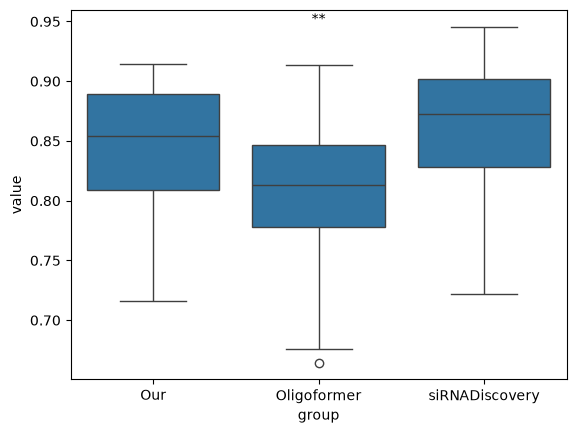

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# p-values
p2 = ttest_ind(final["Our"], final["Oligoformer"], nan_policy="omit").pvalue
p3 = ttest_ind(final["Our"], final["siRNADiscovery"], nan_policy="omit").pvalue

# reshape for seaborn
plot_df = final.melt(
    value_vars=["Our", "Oligoformer", "siRNADiscovery"],
    var_name="group",
    value_name="value",
)

ax = sns.boxplot(data=plot_df, x="group", y="value")


# star helper
def star(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


y = plot_df["value"].max()

# add stars only above b2 / b3 if significant
if star(p2):
    ax.text(1, y, star(p2), ha="center", va="bottom")

if star(p3):
    ax.text(2, y, star(p3), ha="center", va="bottom")
plt.savefig("Comparison.eps")
plt.show()

# Sliding Window

In [71]:
rows = []
outpath = "sliding_window_outfolder/"
for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)

        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append(
                        {
                            "name": name,
                            "win_len": (b := filename[:-5]).split("_")[1],
                            "window_start": int((b := filename[:-5]).split("_")[3]) + 1,
                            "model": model,
                            "metric": metric,
                            "value": value,
                        }
                    )

# Build DataFrame
df = pd.DataFrame(rows)
df = df[(df["model"] == "LGR") & (df["metric"] == "roc_auc")]
df

,name,win_len,window_start,model,metric,value
10,BD135193,3,5,LGR,roc_auc,0.506481
45,NM_001001481,3,5,LGR,roc_auc,0.785714
80,NM_002559,3,5,LGR,roc_auc,0.540020
115,NM_003337,3,5,LGR,roc_auc,0.607378
150,NM_003340,3,5,LGR,roc_auc,0.509028
...,...,...,...,...,...,...
116385,NM_022005,2,3,LGR,roc_auc,0.448864
116420,NM_025237,2,3,LGR,roc_auc,0.514098
116455,NM_053656,2,3,LGR,roc_auc,0.418079
116490,XM_214061,2,3,LGR,roc_auc,0.570266


In [72]:
df_avg = df.groupby(["win_len", "window_start"])["value"].mean().reset_index()
df_avg.head(5)

,win_len,window_start,value
0,1,1,0.728114
1,1,2,0.608385
2,1,3,0.516827
3,1,4,0.508416
4,1,5,0.525061


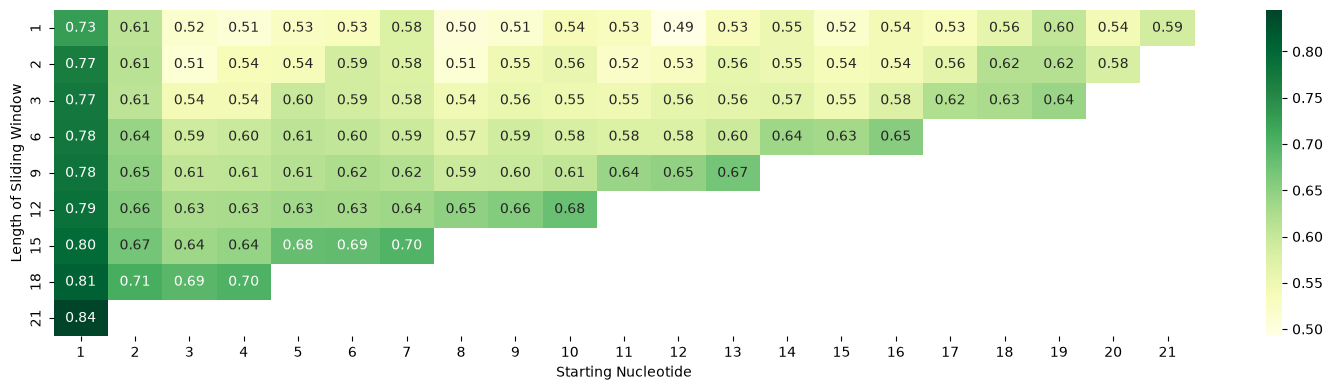

In [73]:
heatmap_data = df_avg.pivot(index="win_len", columns="window_start", values="value")
heatmap_data.index = heatmap_data.index.astype(int)
heatmap_data.columns = heatmap_data.columns.astype(int)

heatmap_data = heatmap_data.sort_index().sort_index(axis=1)

plt.figure(figsize=(15, 4))
sns.heatmap(
    heatmap_data,
    cmap="YlGn",
    annot=True,
    fmt=".2f",  # format (2 decimal places)
)

plt.xlabel("Starting Nucleotide")
plt.ylabel("Length of Sliding Window")
plt.tight_layout()
plt.savefig("sliding_window_results.eps")
plt.show()